# Signed BurstProp — MNIST | Analysis notebook

**Post-training analysis** without rerunning the 100 training epochs. Loads `history.json`, `config.json`, `best.pt`, and `last.pt` from either a ZIP archive or an extracted results directory. Covers learning curves, firing rates, signed burst activity, runtime, weight distributions, receptive fields, and checkpoint comparisons.

**Data limitations:** the recorded `bplus/bminus` fractions are not firing rates and cannot reconstruct individual neuronal events. The files do not contain sample-level spikes, logits, per-digit predictions, or membrane traces. Raster plots, confusion matrices, and dendritic dynamics require additional evaluation or logging.


In [1]:
# Run once if dependencies are missing:
# %pip install numpy pandas matplotlib seaborn torch
import io, json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import torch
from IPython.display import display

# Consistent, colorblind-friendly Seaborn aesthetics for every figure.
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind", font_scale=1.05)
COLORS = sns.color_palette("colorblind", 10)
TRAIN_COLOR, TEST_COLOR, PLUS_COLOR, MINUS_COLOR = COLORS[0], COLORS[1], COLORS[2], COLORS[3]
DIVERGING_CMAP = sns.color_palette("vlag", as_cmap=True)
mpl.rcParams.update({
    "figure.dpi": 125, "savefig.dpi": 300, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "semibold",
    "axes.grid": True, "grid.alpha": 0.18, "grid.linewidth": 0.7,
    "lines.linewidth": 2.2, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
# Point to the original ZIP or extracted directory; common paths are autodetected.
RESULTS_PATH = './results/stuck2025_signed_symetric'  
OUT_DIR = Path('analysis_figures')
OUT_DIR.mkdir(exist_ok=True)
SAVE_FIGURES = True

def savefig(name):
    if SAVE_FIGURES:
        plt.savefig(OUT_DIR / f'{name}.png', bbox_inches='tight')
        plt.savefig(OUT_DIR / f'{name}.pdf', bbox_inches='tight')
    plt.show()

def discover_path():
    candidates = [Path('stuck2025_signed_symetric.zip'), Path('../stuck2025_signed_symetric.zip'),
                  Path('stuck2025_signed_symetric'), Path('../stuck2025_signed_symetric'),
                  Path('results/stuck2025_signed_cudagraph')]
    for p in candidates:
        if p.exists(): return p
    raise FileNotFoundError('Set RESULTS_PATH to the ZIP or directory containing history.json.')

source = Path(RESULTS_PATH) if RESULTS_PATH else discover_path()
if source.is_file() and source.suffix.lower()=='.zip':
    archive = zipfile.ZipFile(source)
    names = archive.namelist()
    def readbytes(filename):
        matches = [x for x in names if x.endswith('/'+filename) or x == filename]
        if len(matches)!=1: raise FileNotFoundError(f'Expected exactly one {filename}; found: {matches}')
        return archive.read(matches[0])
else:
    archive=None
    root = source if (source/'history.json').exists() else next((p for p in source.rglob('history.json')),None)
    if root is None: raise FileNotFoundError(f'Could not find history.json under {source}')
    if root.is_file(): root=root.parent
    def readbytes(filename): return (root/filename).read_bytes()

history = pd.DataFrame(json.loads(readbytes('history.json'))).sort_values('epoch').reset_index(drop=True)
metadata = json.loads(readbytes('config.json'))
config = metadata.get('config', metadata)

def checkpoint(filename):
    raw=readbytes(filename)
    # These checkpoints originate from your training. Do not load untrusted .pt files.
    return torch.load(io.BytesIO(raw), map_location='cpu', weights_only=True)
best, last = checkpoint('best.pt'), checkpoint('last.pt')
W1b,W2b = best['W1'].detach().cpu().numpy(), best['W2'].detach().cpu().numpy()
W1l,W2l = last['W1'].detach().cpu().numpy(), last['W2'].detach().cpu().numpy()
assert W1b.shape==(config['n_hidden'],config['n_input'])
assert W2b.shape==(config['n_output'],config['n_hidden'])
print('Source:', source, '| epochs:',len(history),'| weight shapes:',W1b.shape,W2b.shape)
display(history.head(3))

Source: results\stuck2025_signed_symetric | epochs: 100 | weight shapes: (100, 784) (10, 100)


,epoch,train_acc,test_acc,hidden_rate_hz,output_rate_hz,hidden_bplus_fraction,hidden_bminus_fraction,output_bplus_fraction,output_bminus_fraction,teacher_rate_mse,epoch_seconds,test_seconds
0,1,0.661667,0.7975,28.641240,26.925433,0.011884,0.012294,0.037190,0.042064,2668.675413,990.354232,0.561411
1,2,0.867783,0.8961,33.308973,27.751033,0.011637,0.012091,0.035071,0.042557,1827.729408,988.410606,0.570627
2,3,0.904083,0.9167,32.327337,27.415667,0.011043,0.011538,0.033672,0.042080,1639.748779,992.887694,0.540862


## 1. Summary and learning curves

,Metric,Value
0,Best test accuracy,96.87%
1,Best epoch,81
2,Final test accuracy,96.58%
3,Final train accuracy,96.82%
4,Final generalization gap (pp),0.24
5,Final hidden firing rate (Hz),17.48
6,Final output firing rate (Hz),30.47
7,Training + testing runtime (h),24.89


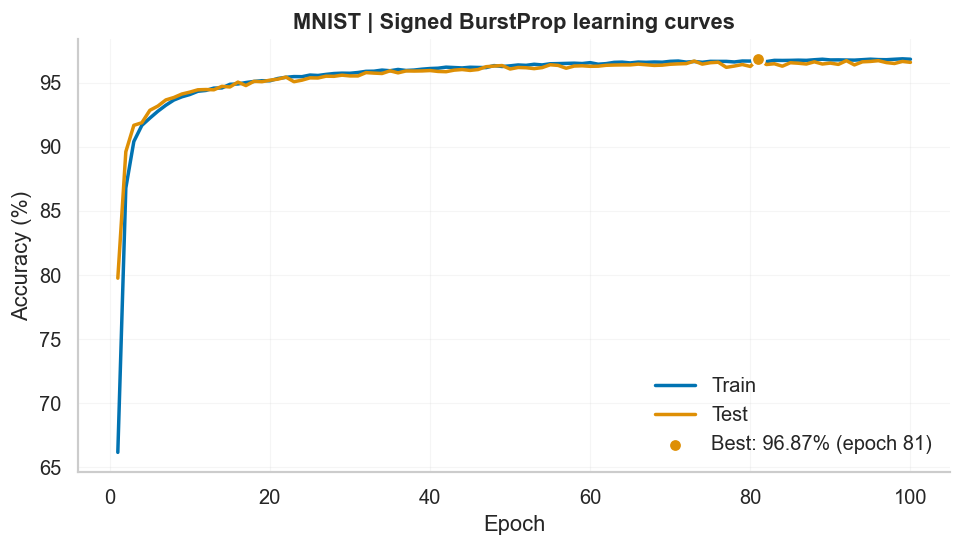

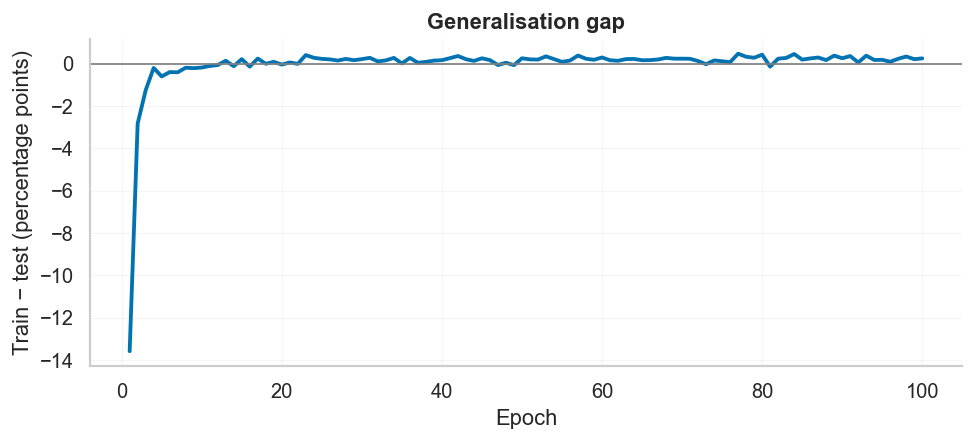

In [2]:
peak = history.loc[history.test_acc.idxmax()]
final=history.iloc[-1]
summary=pd.DataFrame({
    'Metric':['Best test accuracy','Best epoch','Final test accuracy','Final train accuracy',
               'Final generalization gap (pp)','Final hidden firing rate (Hz)','Final output firing rate (Hz)',
               'Training + testing runtime (h)'],
    'Value':[f'{peak.test_acc:.2%}',int(peak.epoch),f'{final.test_acc:.2%}',f'{final.train_acc:.2%}',
             f'{(final.train_acc-final.test_acc)*100:.2f}',f'{final.hidden_rate_hz:.2f}',
             f'{final.output_rate_hz:.2f}',f"{(history.epoch_seconds.sum()+history.test_seconds.sum())/3600:.2f}"]})
display(summary)
fig, ax=plt.subplots(figsize=(9,4.5))
ax.plot(history.epoch,100*history.train_acc,label='Train',lw=2,color=TRAIN_COLOR)
ax.plot(history.epoch,100*history.test_acc,label='Test',lw=2,color=TEST_COLOR)
ax.scatter([peak.epoch],[100*peak.test_acc],s=55,zorder=4,color=TEST_COLOR,edgecolors='white',linewidths=1.2,label=f'Best: {peak.test_acc:.2%} (epoch {int(peak.epoch)})')
ax.set(xlabel='Epoch',ylabel='Accuracy (%)',title='MNIST | Signed BurstProp learning curves')
ax.legend();savefig('01_accuracy')

fig,ax=plt.subplots(figsize=(9,3.4))
ax.plot(history.epoch,100*(history.train_acc-history.test_acc))
ax.axhline(0,color='gray',lw=1)
ax.set(xlabel='Epoch',ylabel='Train − test (percentage points)',title='Generalisation gap')
savefig('02_generalisation_gap')

## 2. Spiking rates and signed bursts

Burst fractions are plotted as recorded by the training script. **They should not be interpreted as conditional probabilities given a spike** unless explicitly defined that way in the training code.

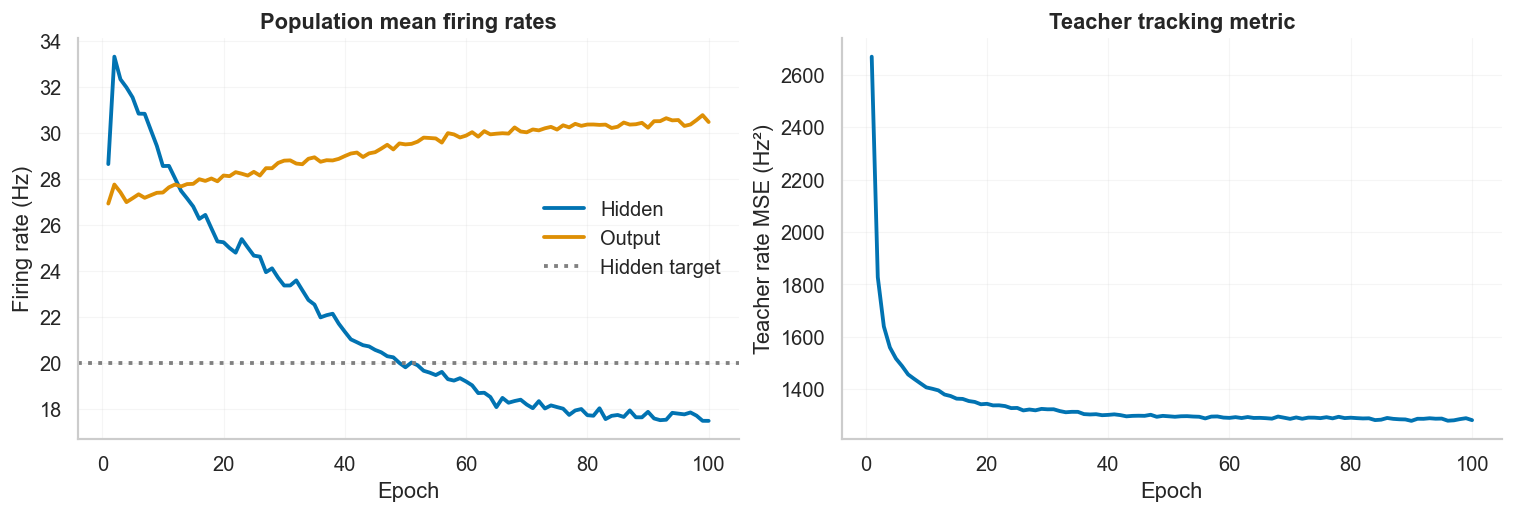

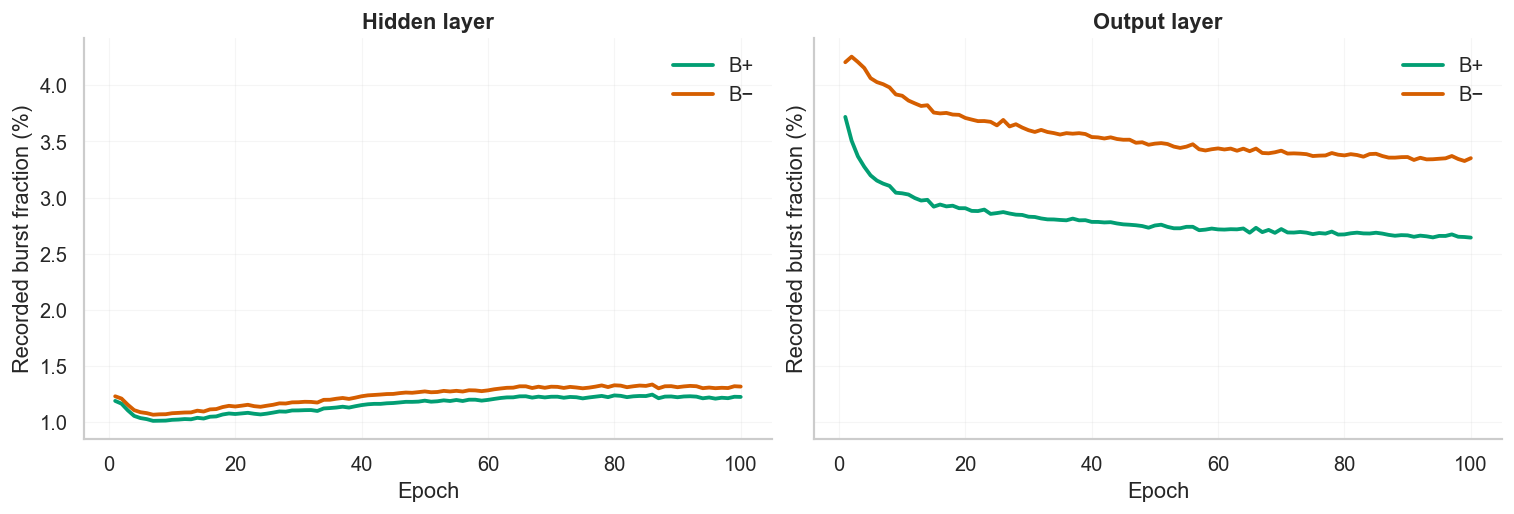

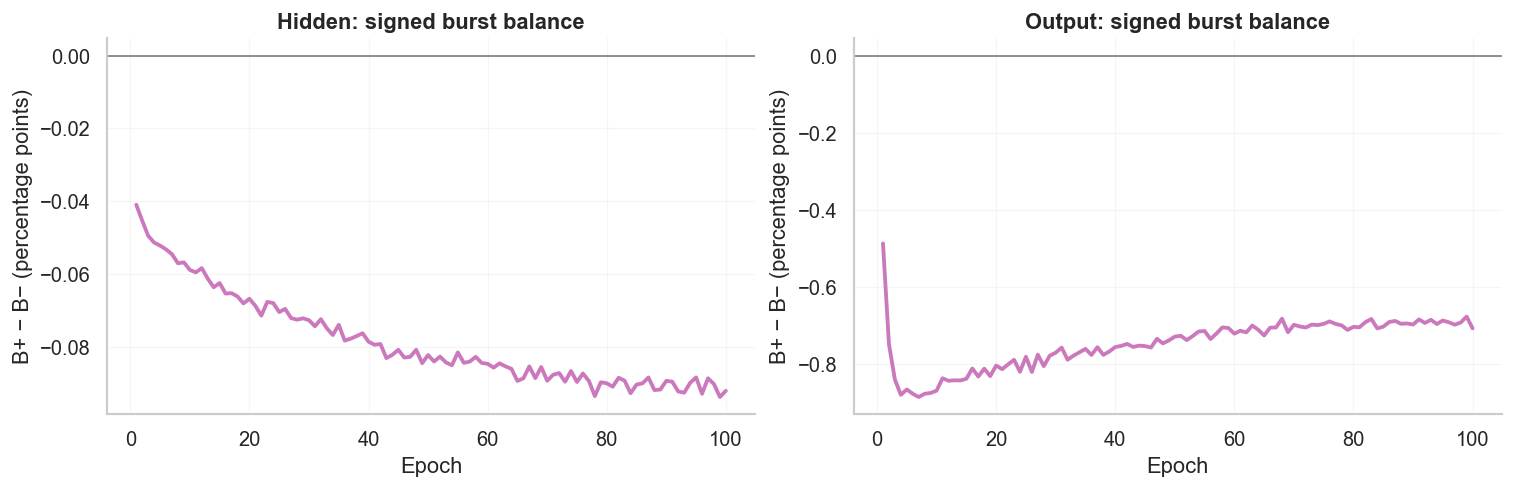

In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axs[0].plot(history.epoch,history.hidden_rate_hz,label='Hidden')
axs[0].plot(history.epoch,history.output_rate_hz,label='Output')
axs[0].axhline(config['hidden_target_hz'],ls=':',color='gray',label='Hidden target')
axs[0].set(xlabel='Epoch',ylabel='Firing rate (Hz)',title='Population mean firing rates');axs[0].legend()
axs[1].plot(history.epoch,history.teacher_rate_mse)
axs[1].set(xlabel='Epoch',ylabel='Teacher rate MSE (Hz²)',title='Teacher tracking metric')
savefig('03_rates_teacher')

fig,axs=plt.subplots(1,2,figsize=(12,4),sharey=True,constrained_layout=True)
for ax,prefix,title in [(axs[0],'hidden','Hidden layer'),(axs[1],'output','Output layer')]:
    plus=history[f'{prefix}_bplus_fraction'];minus=history[f'{prefix}_bminus_fraction']
    ax.plot(history.epoch,100*plus,label='B+',color=PLUS_COLOR)
    ax.plot(history.epoch,100*minus,label='B−',color=MINUS_COLOR)
    ax.set(xlabel='Epoch',ylabel='Recorded burst fraction (%)',title=title);ax.legend()
savefig('04_signed_burst_fractions')

fig,axs=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
for ax,prefix,title in [(axs[0],'hidden','Hidden'),(axs[1],'output','Output')]:
    plus=history[f'{prefix}_bplus_fraction'];minus=history[f'{prefix}_bminus_fraction']
    ax.plot(history.epoch,100*(plus-minus),color=COLORS[4])
    ax.axhline(0,color='gray',lw=1)
    ax.set(xlabel='Epoch',ylabel='B+ − B− (percentage points)',title=f'{title}: signed burst balance')
savefig('05_signed_balance')

## 3. Training runtime

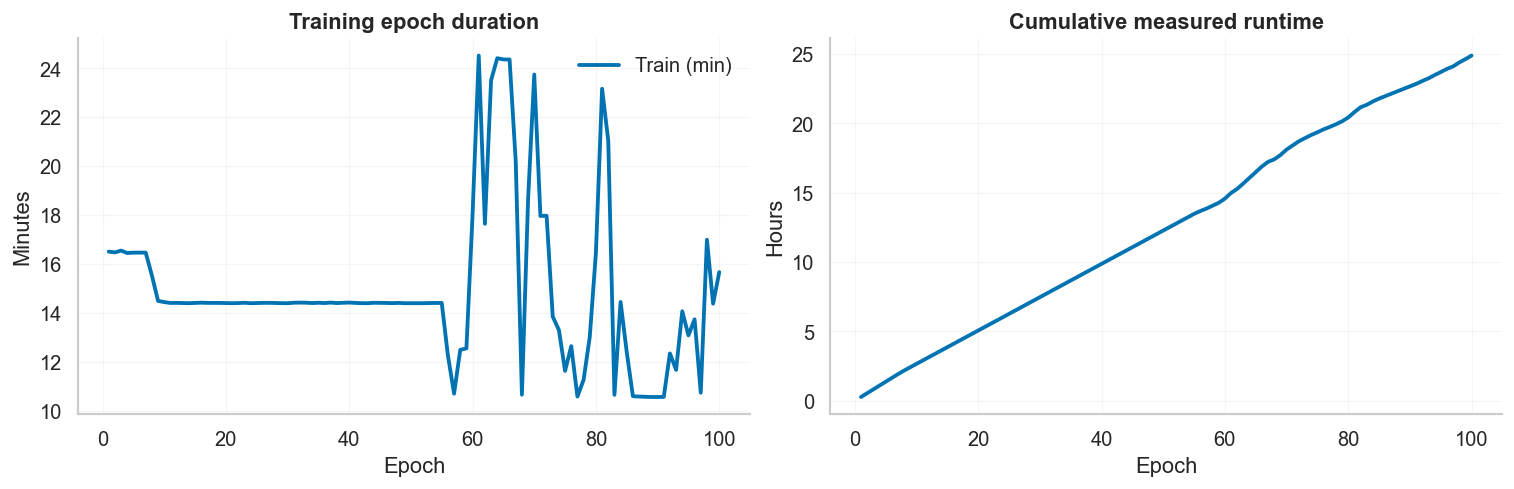

In [4]:
fig,axs=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
axs[0].plot(history.epoch,history.epoch_seconds/60,label='Train (min)')
axs[0].set(xlabel='Epoch',ylabel='Minutes',title='Training epoch duration');axs[0].legend()
axs[1].plot(history.epoch,np.cumsum(history.epoch_seconds+history.test_seconds)/3600)
axs[1].set(xlabel='Epoch',ylabel='Hours',title='Cumulative measured runtime')
savefig('06_runtime')

## 4. Weight distributions and best-to-last checkpoint changes

The `best → last` comparison does **not** measure changes since initialization; the ZIP does not contain an `initial.pt` checkpoint.

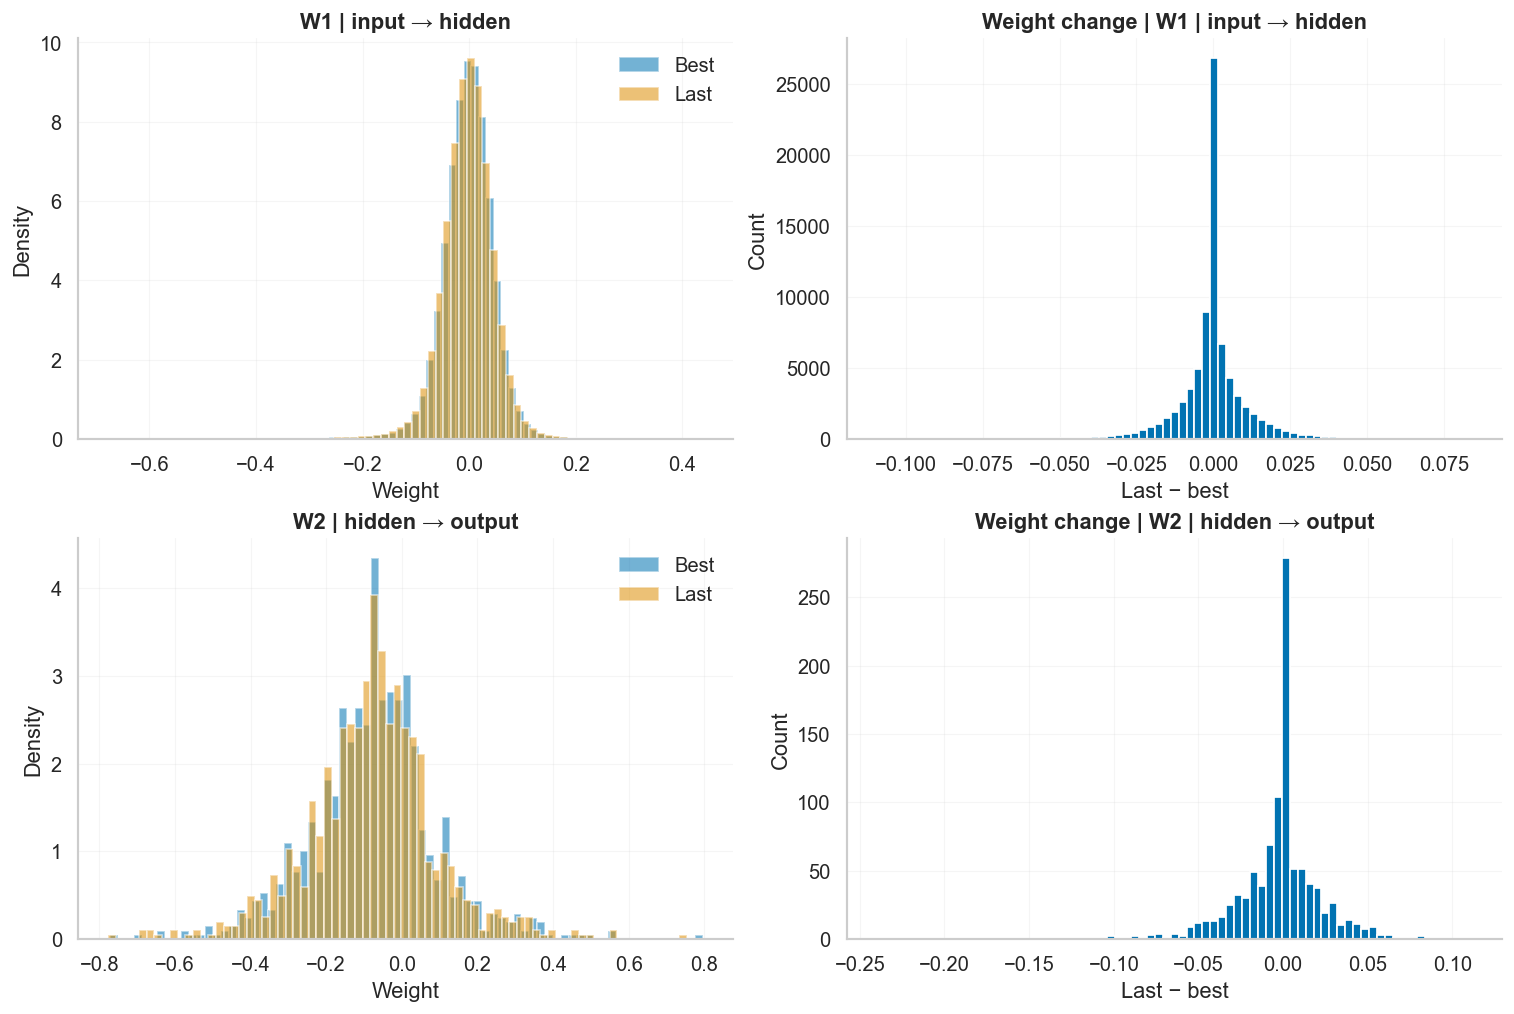

,Layer,Shape,Mean |best|,Mean |last|,Δ Frobenius / ||best||,Fraction positive (best),Fraction positive (last)
0,W1,"(100, 784)",0.03608,0.03670,0.21753,0.49575,0.49668
1,W2,"(10, 100)",0.13718,0.13944,0.14357,0.28900,0.28400


In [5]:
fig,axs=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for row,(b,l,title) in enumerate([(W1b,W1l,'W1 | input → hidden'),(W2b,W2l,'W2 | hidden → output')]):
    axs[row,0].hist(b.ravel(),bins=75,alpha=.55,density=True,label='Best',color=TRAIN_COLOR)
    axs[row,0].hist(l.ravel(),bins=75,alpha=.55,density=True,label='Last',color=TEST_COLOR)
    axs[row,0].set(xlabel='Weight',ylabel='Density',title=title);axs[row,0].legend()
    axs[row,1].hist((l-b).ravel(),bins=75)
    axs[row,1].set(xlabel='Last − best',ylabel='Count',title=f'Weight change | {title}')
savefig('07_weight_distributions')

rows=[]
for name,b,l in [('W1',W1b,W1l),('W2',W2b,W2l)]:
    d=l-b
    rows.append({'Layer':name,'Shape':str(b.shape),'Mean |best|':np.mean(abs(b)),
                 'Mean |last|':np.mean(abs(l)), 'Δ Frobenius / ||best||':np.linalg.norm(d)/(np.linalg.norm(b)+1e-12),
                 'Fraction positive (best)':np.mean(b>0),'Fraction positive (last)':np.mean(l>0)})
display(pd.DataFrame(rows).round(5))

## 5. Receptive fields of the 100 hidden neurons

Each row of `W1` is reshaped into a 28 × 28 image. Signed effective weights are displayed using a shared diverging color scale for comparison.

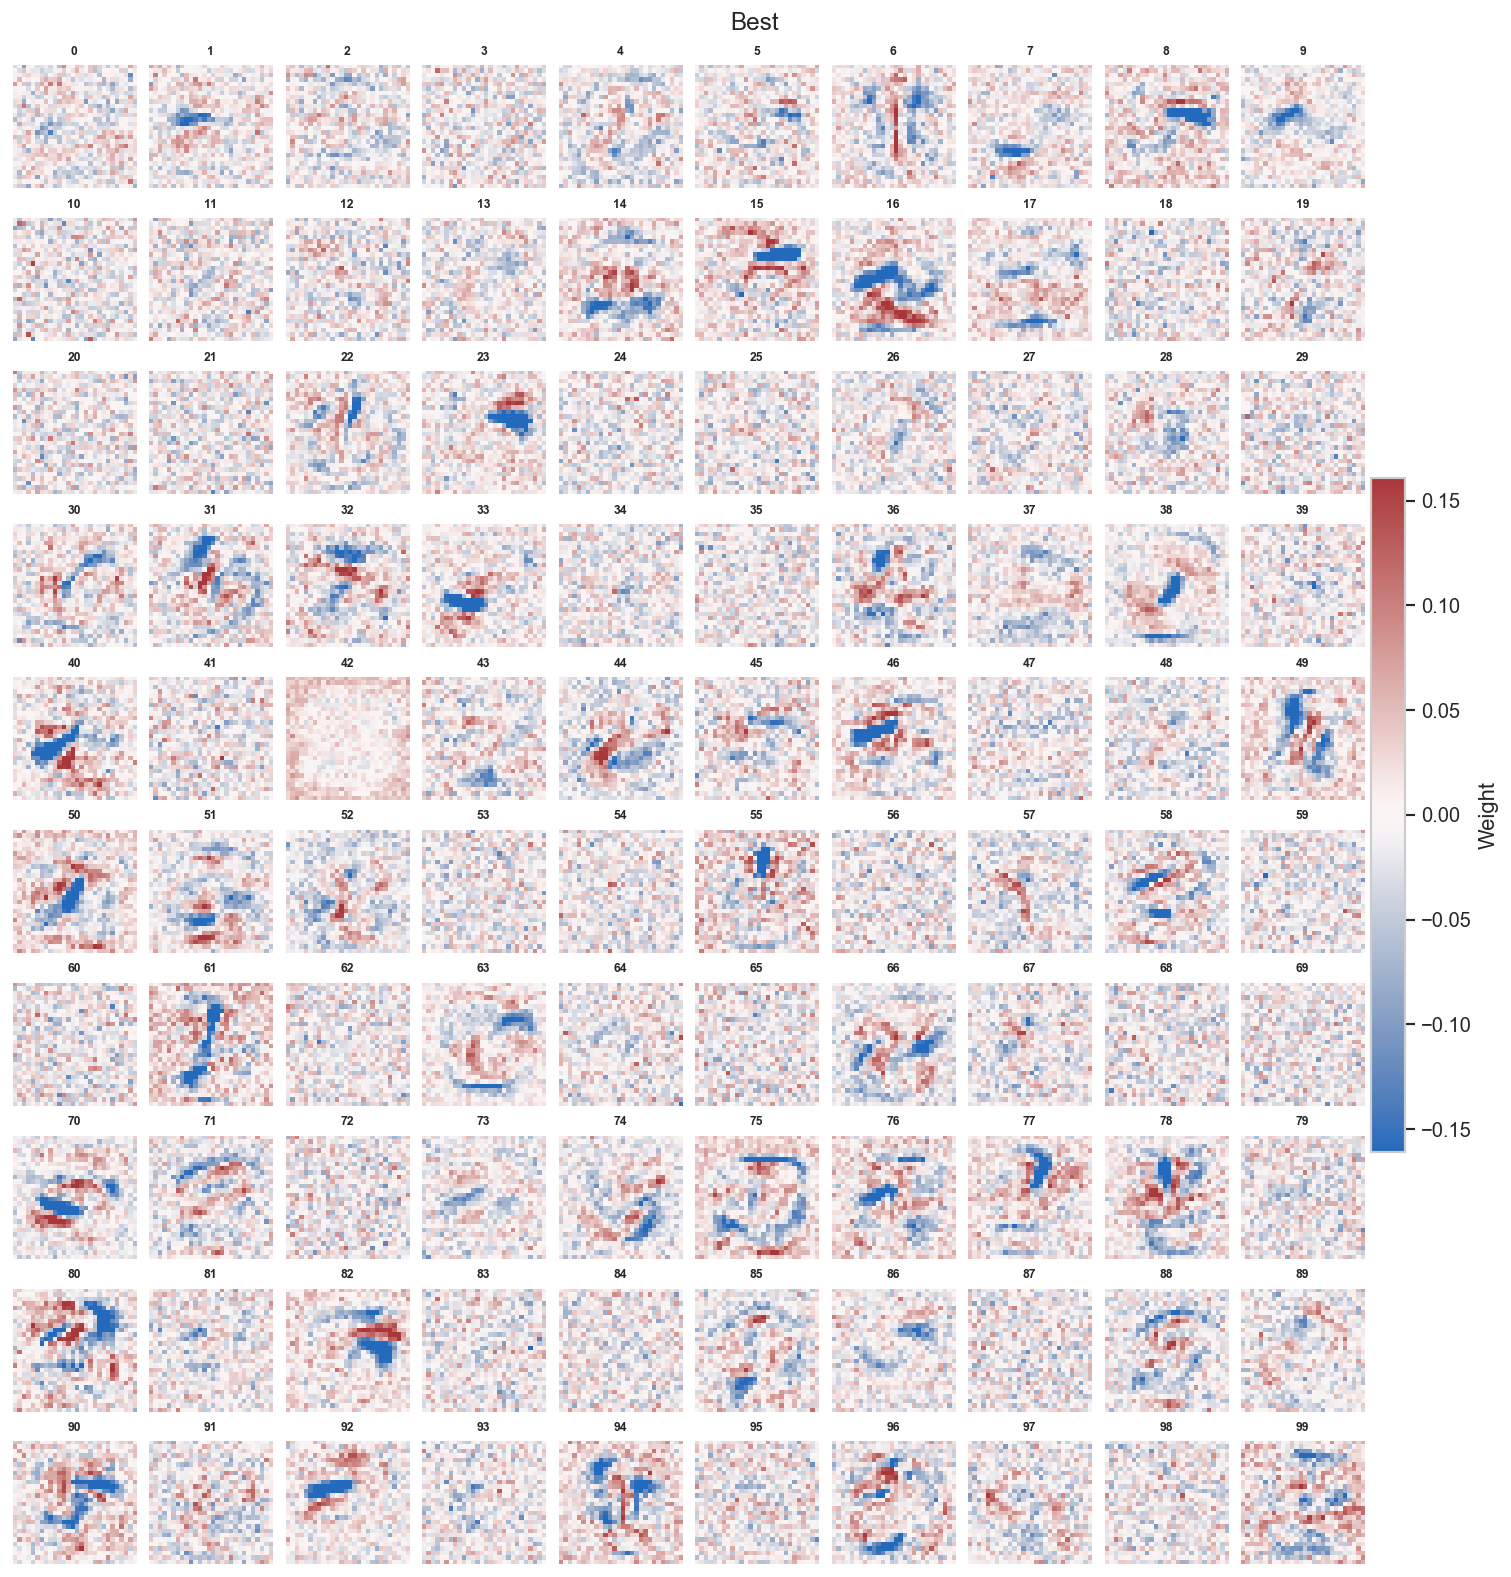

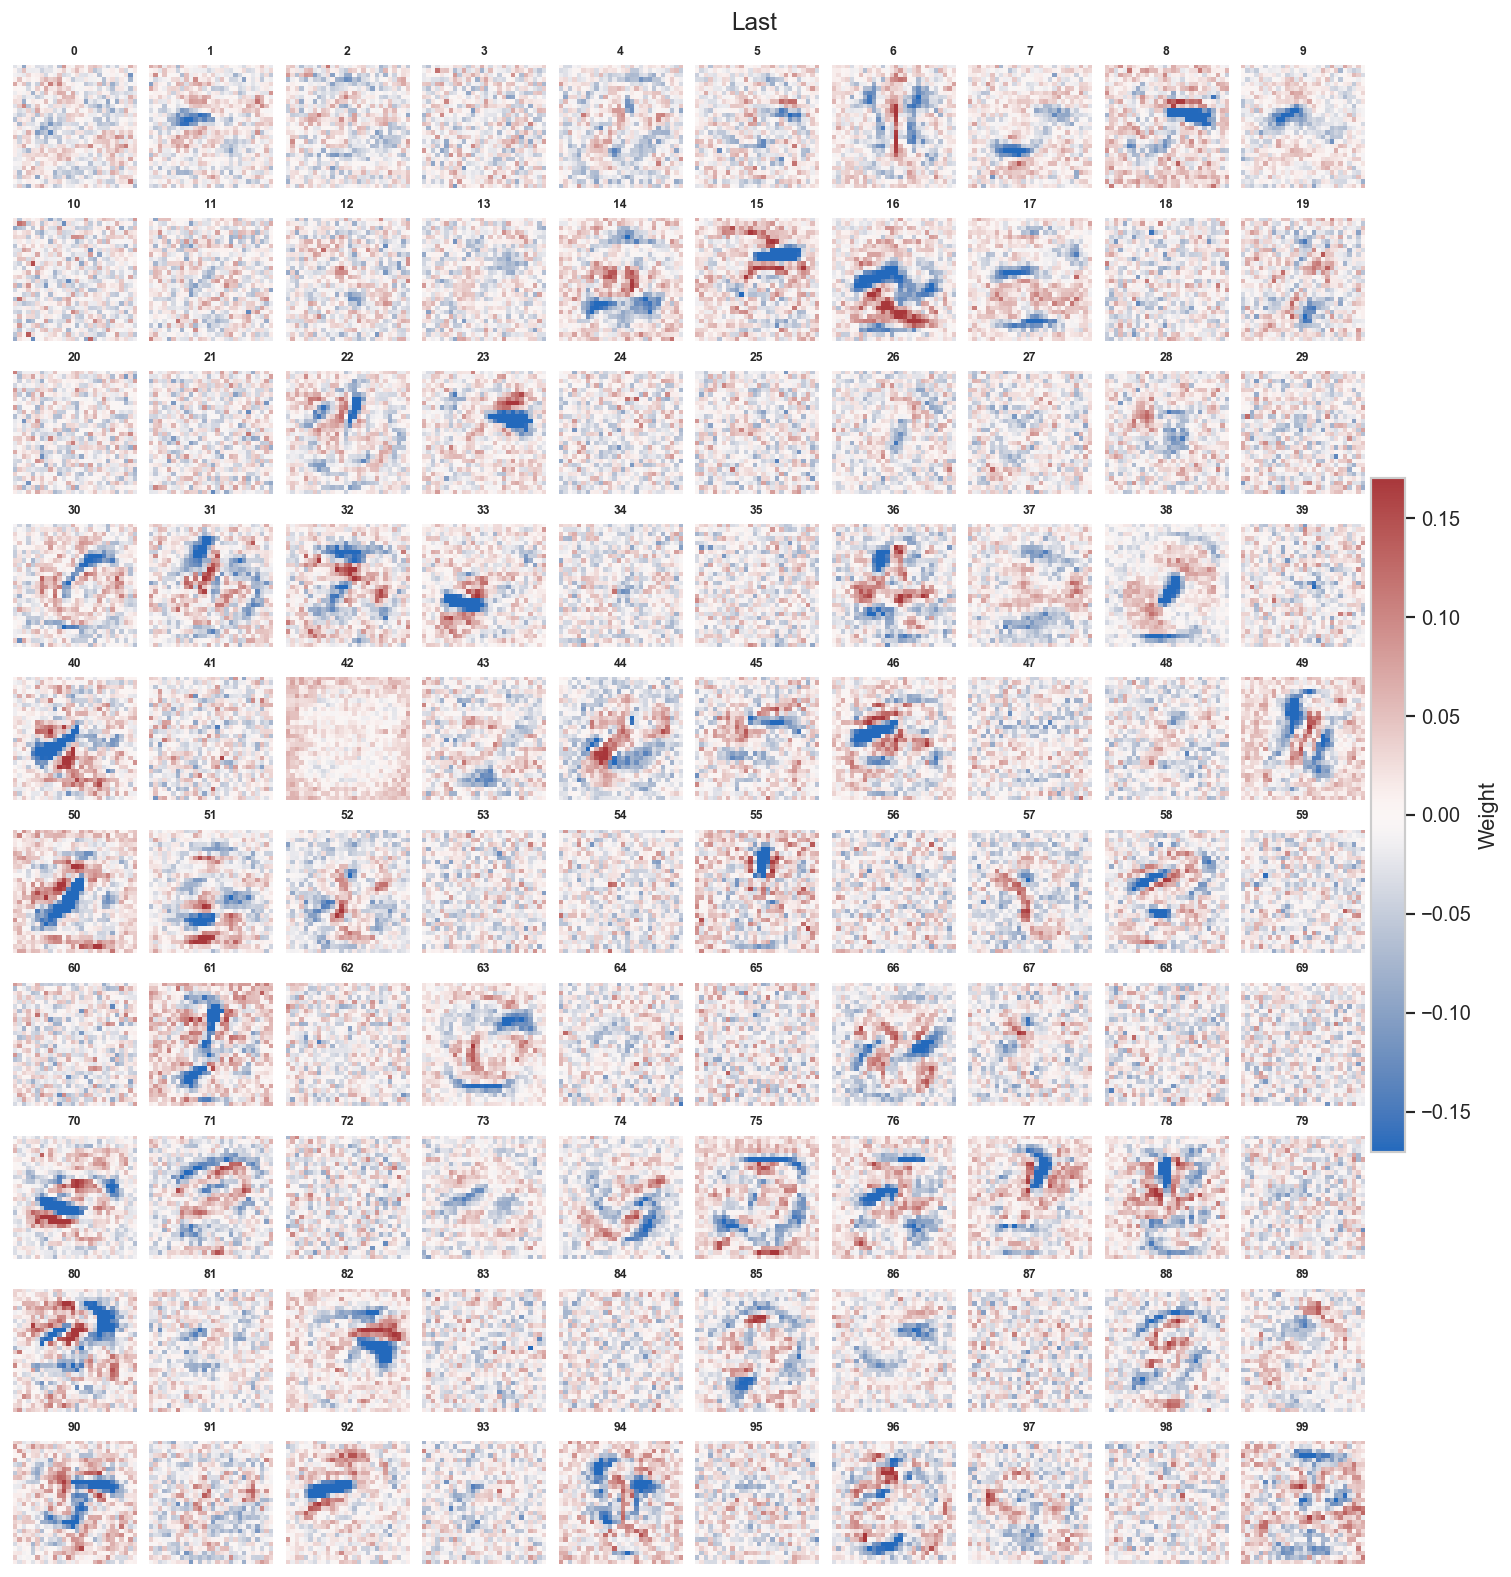

In [6]:
def receptive_fields(W, name, columns=10):
    n = W.shape[0]; rows=int(np.ceil(n/columns))
    fig,axs=plt.subplots(rows,columns,figsize=(12,1.25*rows),constrained_layout=True)
    limit=np.percentile(np.abs(W),99)
    for i,ax in enumerate(np.ravel(axs)):
        ax.axis('off')
        if i<n:
            im=ax.imshow(W[i].reshape(28,28),cmap=DIVERGING_CMAP,vmin=-limit,vmax=limit,interpolation='nearest')
            ax.set_title(str(i),fontsize=7)
    fig.colorbar(im,ax=np.ravel(axs).tolist(),shrink=.45,pad=.005,label='Weight')
    fig.suptitle(name,fontsize=14)
    savefig('08_receptive_fields_'+name.lower().replace(' ','_'))
receptive_fields(W1b,'Best')
receptive_fields(W1l,'Last')

## 6. Output readout and weight geometry

`W2` connects hidden neurons to the 10 output units (digits 0–9). A weight-based preferred class is **not the same as functional stimulus selectivity**, which requires responses to MNIST inputs.

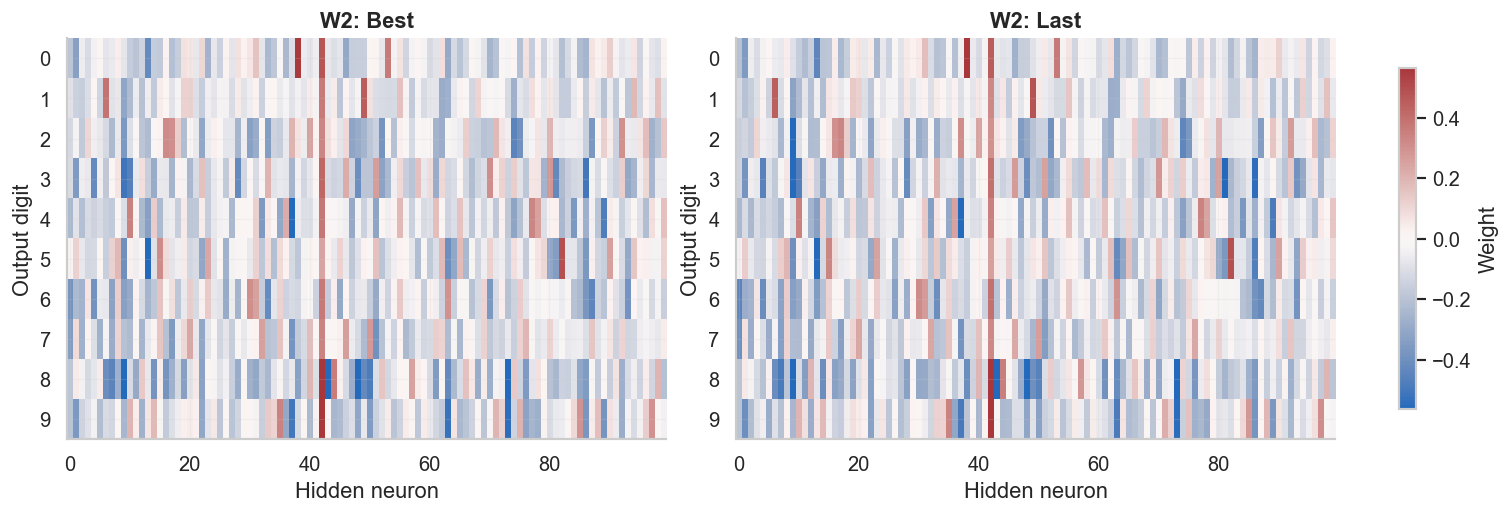

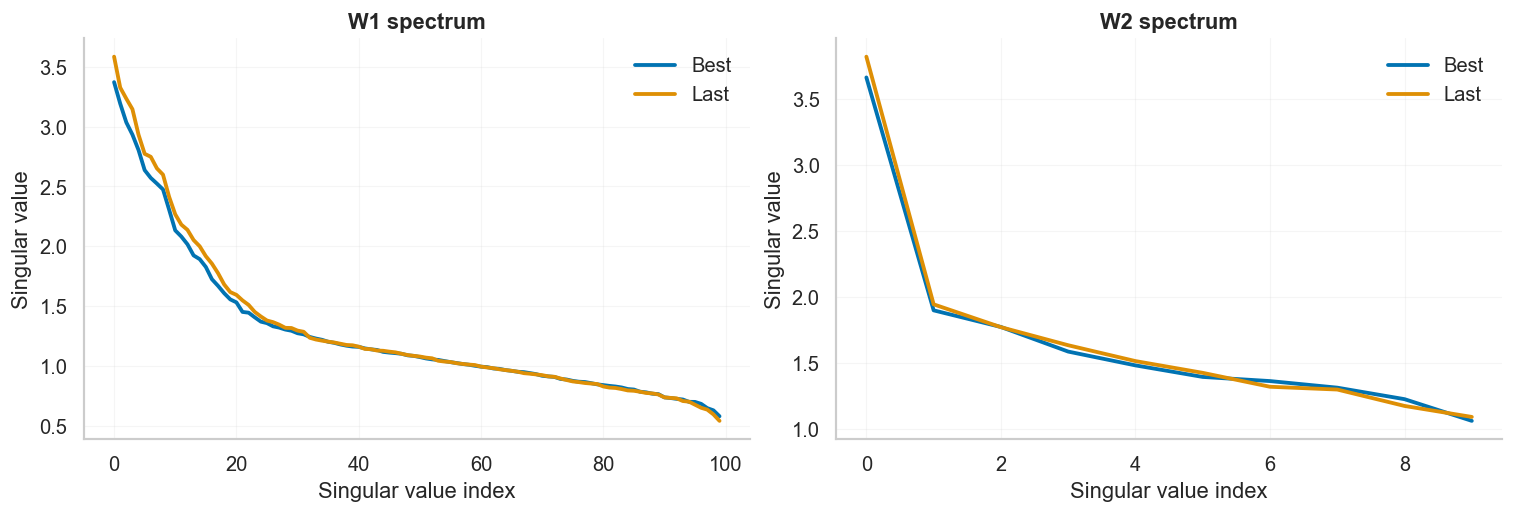

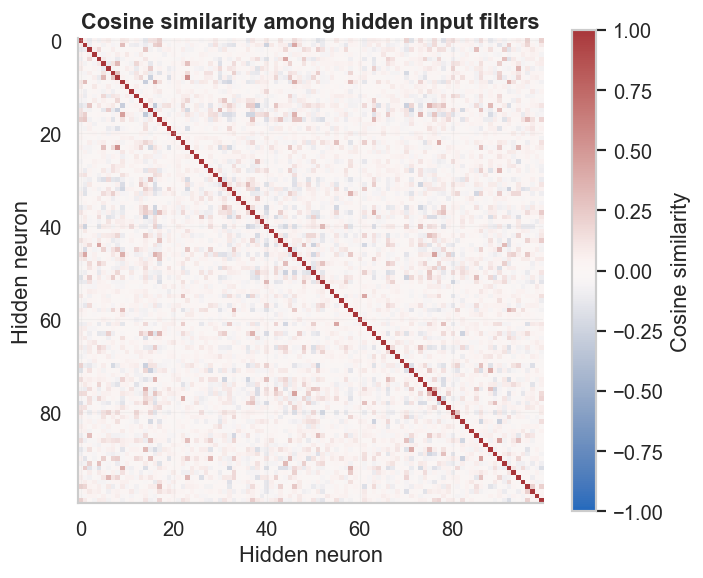

In [7]:
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
vm=max(np.percentile(abs(W2b),99),np.percentile(abs(W2l),99))
for ax,W,name in zip(axs,[W2b,W2l],['Best','Last']):
    im=ax.imshow(W,aspect='auto',cmap=DIVERGING_CMAP,vmin=-vm,vmax=vm)
    ax.set(xlabel='Hidden neuron',ylabel='Output digit',title=f'W2: {name}')
    ax.set_yticks(range(10))
fig.colorbar(im,ax=axs.tolist(),shrink=.85,label='Weight')
savefig('09_readout_weights')

fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,b,l,name in zip(axs,[W1b,W2b],[W1l,W2l],['W1','W2']):
    sb=np.linalg.svd(b,compute_uv=False);sl=np.linalg.svd(l,compute_uv=False)
    ax.plot(sb,label='Best',color=TRAIN_COLOR);ax.plot(sl,label='Last',color=TEST_COLOR)
    ax.set(xlabel='Singular value index',ylabel='Singular value',title=f'{name} spectrum')
    ax.legend()
savefig('10_singular_spectrum')

# Cosine similarity among hidden input receptive fields (best model)
normed = W1b/(np.linalg.norm(W1b,axis=1,keepdims=True)+1e-12)
sim=normed@normed.T
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(sim,cmap=DIVERGING_CMAP,vmin=-1,vmax=1)
ax.set(title='Cosine similarity among hidden input filters',xlabel='Hidden neuron',ylabel='Hidden neuron')
fig.colorbar(im,ax=ax,label='Cosine similarity');savefig('11_filter_similarity')

## 7. Exported results and further analyses

**Extensions using a fresh inference pass (no retraining):** confusion matrix, per-digit accuracy, misclassified examples, class-conditioned spike statistics, noise robustness, and firing-rate/accuracy relationships. These require the forward simulation and MNIST data.

**Extensions requiring new simulation logging:** layer-wise spike rasters, bAP/apical traces, inter-spike-interval histograms, eligibility traces, stepwise weight updates, and temporal alignment between `B+`/`B−` events and synaptic updates.

**Methodological caveat:** the best checkpoint was selected by test accuracy. For publication-quality evaluation, use an independent validation set for checkpoint selection and reserve the test set for final assessment; repeat across random seeds and report uncertainty.

In [8]:
history.to_csv(OUT_DIR/'history.csv',index=False)
summary.to_csv(OUT_DIR/'summary.csv',index=False)
print('Figures and tables saved to:',OUT_DIR.resolve())
print('Generated:',len(list(OUT_DIR.glob('*.png'))),'PNG +',len(list(OUT_DIR.glob('*.pdf'))),'PDF')

Figures and tables saved to: \\fs-ncl-smb-db\home-home2022\c3055922\Desktop\Github\spikingbursprop\analysis_figures
Generated: 12 PNG + 12 PDF
